# 52 -- Chemprop + CheMeleon with the QM data at BOTH the molecule and the per-atom level

Every QM experiment on this project so far has fed the quantum data to a model as **columns of a
table**, and every one has come back negative. Notebook 44 gave Chemprop the molecule-level block
as extra descriptors (`plain_qm`) and got `p_BH = 0.82` on all four isoforms. Notebook 18 did the
same with a charge descriptor and got a clean tie. Notebook 46 ran six tabular QM blocks on the
frozen cluster-disjoint partition and returned `DETECTED_NOT_MATERIAL`, with all ten significant
cells under their materiality bars. Notebook 49 then explained why that strand kept failing: those
blocks correlate **0.995 to 0.997** with a ridge arm carrying no quantum content at all, because
they are 239-column models of which 226 columns are the free 2D descriptors. Thirteen columns
cannot out-shout 226.

**The entire bet of this notebook is that a per-atom feature is a different proposition.** It
attaches to the atom, enters the message passing, and travels to that atom's neighbours. It is not
competing with 226 other columns for a linear model's attention; it changes what the graph says
about a particular nitrogen. That has never been tried here.

The molecule-level half is included because it is free (the same forward pass), and because it
makes this arm a strict superset of `plain_qm` rather than a second, incomparable thing. It is
**not** expected to contribute: notebook 44 already measured it at null.

**The feature set, used identically in stages 1 and 2:**

| level | content | route |
|---|---|---|
| graph | `canonical_smiles`, Chemprop's own atom and bond features, V2 featurizer | `-s canonical_smiles` |
| molecule | notebook 44's **13** genuinely-new QM columns (not the unscreened 18 `plain_qm` used) | `--descriptors-columns` |
| atom | `q_hirshfeld` and `mayer_va`, per atom | `--atom-features-path` |

Deliberately absent: **notebook 45's four aggregate atom descriptors.** They are summaries of these
same per-atom values (`hirshfeld_C_min`, `hirshfeld_H_min`, `bond_order_min`, `mayer_va_min` are all
reductions over the columns this notebook now feeds atom by atom), so passing both would be passing
one quantity twice -- once raw and once pre-reduced -- and would make any effect unattributable.
No bond features either: bond ordering is a second ordering problem and can wait.

**Three stages. This notebook currently contains stage 0 only, and stage 0 ends in a decision
point that is the user's, not mine.**

0. Ordering, features, wiring. The atom ordering is the whole risk, and the wiring check is the
   gate that decides whether stage 1 is worth four to five hours.
1. 25 folds on the frozen cluster-disjoint partition, against notebook 37's stored `plain`.
2. Full-data fit, blind predictions, both correction layers, a validated submission file.

**`SEND` is False throughout and nothing is transmitted.**

## Part 0 -- setup and provenance

In [1]:
# Part 0.1 -- setup, provenance, and the environment assertions this project requires.
import hashlib, importlib.util, json, os, re, subprocess, sys, textwrap, warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

# Notebook 34 established that restricting BLAS/OMP to one thread changes floating-point
# reduction order and so chemprop's training trajectory. OMP_NUM_THREADS is ASSERTED unset;
# KMP_DUPLICATE_LIB_OK is only REPORTED, because `import xgboost` sets it and an assertion
# after imports is unsatisfiable (notebook 40's own re-run bug).
assert os.environ.get("OMP_NUM_THREADS") is None, "OMP_NUM_THREADS must be unset"
print("OMP_NUM_THREADS      : unset (asserted)")
print(f"KMP_DUPLICATE_LIB_OK : {os.environ.get('KMP_DUPLICATE_LIB_OK')!r} (reported, not asserted)")

SEND = False
print(f"SEND                 : {SEND}  (nothing is transmitted anywhere in this notebook)")

OUT = REPO / "outputs" / "52_chemprop_qm_atom_features"
FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
NB37 = REPO / "outputs" / "37_butina_5x5_complete"
NB44 = REPO / "outputs" / "44_qm_molecular_block"
NB45 = REPO / "outputs" / "45_atom_level_screen"
NB46 = REPO / "outputs" / "46_qm_arm"
QM_PARSED = REPO / "outputs" / "qm_parsed"
CURATED = REPO / "data" / "processed" / "train_inhibition_curated.csv"
BLIND = REPO / "data" / "processed" / "test_blinded_curated.csv"
BUTINA = REPO / "data" / "folds" / "cv_folds_butina_5x5.csv"
NB34_FOLD_SHA256 = "52f39b1a1cea9200b58dce0a061d4a21ce94d9d58ec77067cf6508b0f4b3e87e"

ISOFORMS = ["CYP1A2", "CYP2C9", "CYP2D6", "CYP3A4"]
EP = {i: f"{i}_pIC50_direct_inhibition" for i in ISOFORMS}

RUN_STARTED_AT = datetime.now(timezone.utc)
_pre = subprocess.run(["git", "status", "--porcelain"], cwd=REPO, capture_output=True, text=True)
PRE_DIRTY = sorted(l[3:].strip() for l in _pre.stdout.splitlines() if not l.startswith("??"))
(OUT / "run_meta.json").write_text(json.dumps(
    {"run_started_at_utc": RUN_STARTED_AT.isoformat(), "pre_existing_dirty_tracked_paths": PRE_DIRTY,
     "send": SEND}, indent=2) + "\n")


def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for c in iter(lambda: f.read(1 << 20), b""):
            h.update(c)
    return h.hexdigest()


assert sha256(BUTINA) == NB34_FOLD_SHA256, "the frozen partition is not the file 34/35/37 ran on"
print(f"\ncv_folds_butina_5x5.csv sha256 asserted against notebook 34's record: MATCH")

import chemprop
CP = Path(chemprop.__file__).parent
print(f"chemprop             : {chemprop.__version__} at {CP}")
print(f"run started          : {RUN_STARTED_AT.isoformat(timespec='seconds')}")
print(f"pre-existing dirty tracked paths (subtracted by the scope check): {len(PRE_DIRTY)}")

OMP_NUM_THREADS      : unset (asserted)
KMP_DUPLICATE_LIB_OK : None (reported, not asserted)
SEND                 : False  (nothing is transmitted anywhere in this notebook)

cv_folds_butina_5x5.csv sha256 asserted against notebook 34's record: MATCH


chemprop             : 2.3.1 at /Users/codiefreeman/miniconda3-arm64/envs/cyp-admet-v2/lib/python3.11/site-packages/chemprop
run started          : 2026-10-11T14:43:48+00:00
pre-existing dirty tracked paths (subtracted by the scope check): 22


### Part 0.2 -- the premise the brief could not have known: CheMeleon refuses per-atom features

The task specifies CheMeleon **and** per-atom features. In chemprop 2.3.1 those two are mutually
exclusive through the documented route, and the refusal is explicit rather than a silent failure.

The cell below establishes this three ways: from chemprop's own source, from the published
checkpoint's weight shapes, and from a real CLI invocation.

In [2]:
# Part 0.2 -- the refusal, from chemprop's source, the checkpoint, and a live CLI call.
train_src = (CP / "cli" / "train.py").read_text()

# (a) the source. The guard and the three arguments it refuses.
i = train_src.index("case FoundationModels.CHEMELEON:")
block = train_src[train_src.rindex("if not local_foundation:", 0, i):i + 1400]
print("chemprop/cli/train.py, the CheMeleon-specific validation:\n")
print(textwrap.indent("\n".join(l for l in block.splitlines()
                                if "atom_features_path" in l or "atom_descriptors_path" in l
                                or "bond_features_path" in l or "does not support" in l
                                or "local_foundation" in l), "    "))
assert "CheMeleon does not support passing" in block

# The guard is `if not local_foundation:` -- so the refusal applies to the model NAME only.
assert "if not local_foundation:" in train_src

# (b) the published checkpoint. The reason the refusal is structural rather than arbitrary.
import torch
CKPT = Path.home() / ".chemprop" / "chemeleon_mp.pt"
ck = torch.load(CKPT, weights_only=True)
hp, sd = ck["hyper_parameters"], ck["state_dict"]
print(f"\n\nCheMeleon's published checkpoint ({CKPT.name}, sha256 {sha256(CKPT)[:16]}):")
print(f"  hyper_parameters : d_v={hp['d_v']} d_e={hp['d_e']} d_h={hp['d_h']} "
      f"depth={hp['depth']} d_vd={hp['d_vd']}")
for k, v in sd.items():
    print(f"  {k:12s} {tuple(v.shape)}")
from chemprop.featurizers import MultiHotAtomFeaturizer
assert len(MultiHotAtomFeaturizer.v2()) == hp["d_v"] == 72
print(f"\n  W_i is (d_h, d_v + d_e) = (2048, {hp['d_v']} + {hp['d_e']}) = "
      f"{tuple(sd['W_i.weight'].shape)}, and the V2 atom featurizer is exactly {hp['d_v']} wide.")
print("  So one extra atom feature widens an input the pretrained projection cannot accept.")

# (c) a real CLI call, so this is not an argument from reading code.
TMP = OUT / "flag_probe"; TMP.mkdir(parents=True, exist_ok=True)
smis = ["CCO", "c1ccccc1", "CC(=O)O", "CCN", "CCCl", "c1ccncc1", "CC(C)O", "CCBr"]
pd.DataFrame({"smiles": smis, "y": np.linspace(4, 6, len(smis)),
              "sp": ["train"] * 6 + ["val"] * 2}).to_csv(TMP / "probe.csv", index=False)
from rdkit import Chem, RDLogger
RDLogger.DisableLog("rdApp.*")
np.savez(TMP / "probe_atoms.npz",
         *[np.random.RandomState(0).randn(Chem.MolFromSmiles(s).GetNumAtoms(), 2) for s in smis])
BASE = ["chemprop", "train", "-i", str(TMP / "probe.csv"), "-s", "smiles",
        "--target-columns", "y", "--splits-column", "sp", "-t", "regression",
        "--multi-hot-atom-featurizer-mode", "V2", "--epochs", "5", "--patience", "5",
        "--accelerator", "cpu", "--devices", "1"]
r = subprocess.run(BASE + ["--from-foundation", "CHEMELEON",
                           "--atom-features-path", str(TMP / "probe_atoms.npz"),
                           "-o", str(TMP / "named")], capture_output=True, text=True)
err = [l for l in (r.stdout + r.stderr).splitlines() if "ArgumentError" in l or "does not support" in l]
print(f"\n\n`--from-foundation CHEMELEON --atom-features-path ...` exits {r.returncode}:")
for l in err:
    print("   ", l.strip())
assert r.returncode != 0 and any("does not support passing --atom-features-path" in l for l in err)
print("\nCONFIRMED empirically, not inferred. The documented route is closed.")

chemprop/cli/train.py, the CheMeleon-specific validation:

    if not local_foundation:
                            (args.atom_features_path, "--atom-features-path"),
                            (args.atom_descriptors_path, "--atom-descriptors-path"),
                            (args.bond_features_path, "--bond-features-path"),
                                    message=f"CheMeleon does not support passing {arg_name}",


CheMeleon's published checkpoint (chemeleon_mp.pt, sha256 c376624d3407204e):
  hyper_parameters : d_v=72 d_e=14 d_h=2048 depth=6 d_vd=None
  W_i.weight   (2048, 86)
  W_h.weight   (2048, 2048)
  W_o.weight   (2048, 2120)
  W_o.bias     (2048,)

  W_i is (d_h, d_v + d_e) = (2048, 72 + 14) = (2048, 86), and the V2 atom featurizer is exactly 72 wide.
  So one extra atom feature widens an input the pretrained projection cannot accept.




`--from-foundation CHEMELEON --atom-features-path ...` exits 1:
    raise ArgumentError(
    argparse.ArgumentError: CheMeleon does not support passing --atom-features-path

CONFIRMED empirically, not inferred. The documented route is closed.


### Part 0.3 -- which flag, decided from chemprop 2.3.1's behaviour rather than from the paper

The brief asks which of `--atom-features-path` and `--atom-descriptors-path` puts values **into**
message passing. The help strings say "before" and "after", but a help string is documentation; the
cell below reads the two code paths the tensors actually travel.

In [3]:
# Part 0.3 -- V_f enters before W_i; V_d is concatenated after the last message passing step.
mol_src = (CP / "featurizers" / "molgraph" / "molecule.py").read_text()
mix_src = (CP / "nn" / "message_passing" / "mixins.py").read_text()
base_src = (CP / "nn" / "message_passing" / "base.py").read_text()

print("--atom-features-path  ->  V_f  ->  featurizers/molgraph/molecule.py")
for l in mol_src.splitlines():
    if "atom_features_extra" in l and ("hstack" in l or "torch.cat" in l):
        print("   ", l.strip())
assert "V = np.hstack((V, atom_features_extra))" in mol_src
print("    ...the extra columns are hstacked onto the atom feature matrix V, so d_v grows.")

print("\n    nn/message_passing/mixins.py -- what W_i is applied to:")
for l in mix_src.splitlines():
    if "self.W_i" in l:
        print("   ", l.strip())
assert "self.W_i(torch.cat([bmg.V[bmg.edge_index[0]], bmg.E], dim=1))" in mix_src
print("    So V_f is inside the FIRST projection and every one of the 6 message passing steps.")

print("\n--atom-descriptors-path  ->  V_d  ->  nn/message_passing/base.py::finalize")
fin = base_src[base_src.index("    def finalize("):]
fin = fin[:fin.index("    def forward(")]
for l in fin.splitlines():
    if "W_o(" in l or "W_d(" in l:
        print("   ", l.strip())
assert "H = self.W_o(torch.cat((V, M), dim=1))" in fin
assert "H = self.W_d(torch.cat((H, V_d), dim=1))" in fin
print("    `finalize` runs ONCE, after the message passing loop, on the final messages M.")
print("    V_d therefore never reaches a neighbouring atom. It is a per-atom read-out, not an input.")

DECISION_FLAG = "--atom-features-path"
print(f"\nDECISION: {DECISION_FLAG}. It is the only one of the two that enters message passing,")
print("which is the entire mechanism this notebook is testing.")

--atom-features-path  ->  V_f  ->  featurizers/molgraph/molecule.py
    V = np.hstack((V, atom_features_extra))
    atom_feats = torch.cat((atom_feats, atom_features_extra), dim=1)
    ...the extra columns are hstacked onto the atom feature matrix V, so d_v grows.

    nn/message_passing/mixins.py -- what W_i is applied to:
    return self.W_i(torch.cat([bmg.V[bmg.edge_index[0]], bmg.E], dim=1))
    return self.W_i(bmg.V[bmg.edge_index[0]])
    So V_f is inside the FIRST projection and every one of the 6 message passing steps.

--atom-descriptors-path  ->  V_d  ->  nn/message_passing/base.py::finalize
    H = self.W_o(torch.cat((V, M), dim=1))  # V x d_o
    H = self.W_d(torch.cat((H, V_d), dim=1))  # V x (d_o + d_vd)
    `finalize` runs ONCE, after the message passing loop, on the final messages M.
    V_d therefore never reaches a neighbouring atom. It is a per-atom read-out, not an input.

DECISION: --atom-features-path. It is the only one of the two that enters message passing,
whi

### Part 0.4 -- the route through, and a scaling defect it exposes

`if not local_foundation:` guards the refusal, so it applies to the foundation model's **name**, not
to a local file; and the local path takes only `message_passing` and `agg` from that file. So the
route through is to write a local foundation file holding **CheMeleon's own weights with two extra
columns of zeros** inserted where the featurizer appends the extra features. At initialisation the
result is numerically identical to CheMeleon for any value of those features, because their weights
are exactly zero -- the pretrained encoder is preserved bit for bit, and the only new parameters
are the two columns, which training can then move off zero.

Taking that route surfaced a second, more dangerous thing, which is the reason this notebook scales
the per-atom values itself.

In [4]:
# Part 0.4a -- the widened encoder, and its at-init identity with CheMeleon.
aa_spec = importlib.util.spec_from_file_location("nb52_atom_arrays",
                                                 REPO / "scripts" / "52_atom_arrays.py")
aa = importlib.util.module_from_spec(aa_spec); aa_spec.loader.exec_module(aa)

enc = json.loads((OUT / "widened_encoder.json").read_text()) \
    if (OUT / "widened_encoder.json").exists() else \
    aa.build_widened_chemeleon(aa.K_ATOM_FEATURES, OUT / "chemeleon_widened.pt")
print("the widened local foundation file:")
for k in ("k", "d_v_original", "d_v_widened", "W_i_shape", "W_o_shape",
          "max_abs_diff_vs_chemeleon_at_init"):
    print(f"  {k:36s} {enc[k]}")
assert enc["max_abs_diff_vs_chemeleon_at_init"] == 0.0
print("\n  The at-init check is run on a real molecule with RANDOM extra feature values, so it")
print("  cannot pass merely because the features happened to be zero. 0.0 exactly.")
print("  `agg` is MeanAggregation, matching what the remote CheMeleon path builds -- the local")
print("  path reads agg from the file, so it has to be set deliberately.")

the widened local foundation file:
  k                                    2
  d_v_original                         72
  d_v_widened                          74
  W_i_shape                            [2048, 88]
  W_o_shape                            [2048, 2122]
  max_abs_diff_vs_chemeleon_at_init    0.0

  The at-init check is run on a real molecule with RANDOM extra feature values, so it
  cannot pass merely because the features happened to be zero. 0.0 exactly.
  `agg` is MeanAggregation, matching what the remote CheMeleon path builds -- the local
  path reads agg from the file, so it has to be set deliberately.


In [5]:
# Part 0.4b -- THE SCALING DEFECT. chemprop computes an atom-feature scaler, logs it, and then
# fails to attach it to a foundation-loaded encoder. Training is scaled; predict is not.
print("cli/train.py -- the scaler is fitted on the TRAIN split only:")
for l in train_src.splitlines():
    if 'normalize_inputs("V_f"' in l or "Atom features for mol" in l:
        print("   ", l.strip())

print("\n...and `graph_transform=` is assigned ONLY in the non-foundation branch:")
for n, l in enumerate(train_src.splitlines(), 1):
    if "graph_transform=graph_transforms[" in l:
        print(f"    line {n}: {l.strip()}")
nofound = train_src[train_src.index("    else:\n        mp_cls = AtomMessagePassing"):]
assert "graph_transform=graph_transforms[0]" in nofound
found = train_src[train_src.index("    if args.from_foundation is not None:"):
                  train_src.index("    else:\n        mp_cls = AtomMessagePassing")]
assert "graph_transform" not in found, "the foundation branch would have to assign it"
print("    The foundation branch contains no `graph_transform` assignment at all.")

print("\ndatasets.py -- normalize_inputs MUTATES the training arrays in place:")
ds = (CP / "data" / "datasets.py").read_text()
assert 'self.V_fs = [scaler.transform(V_f) if V_f.size > 0 else V_f for V_f in self._V_fs]' in ds
print('    self.V_fs = [scaler.transform(V_f) ... for V_f in self._V_fs]')
print("    so TRAINING sees scaled features while the saved checkpoint carries nn.Identity,")
print("    and `chemprop predict` therefore feeds the same features UNSCALED.")

# Demonstrated on two real checkpoints, both written by a CLI run in this notebook's own fixture.
from chemprop.models import MPNN
for tag, extra in [("foundation", ["--from-foundation", str(OUT / "chemeleon_widened.pt")]),
                   ("no-foundation", [])]:
    d = TMP / f"gt_{tag.replace('-', '_')}"
    if not (d / "model_0" / "best.pt").exists():
        subprocess.run(BASE + extra + ["--atom-features-path", str(TMP / "probe_atoms.npz"),
                                       "-o", str(d)], capture_output=True, text=True)
    gt = MPNN.load_from_file(d / "model_0" / "best.pt", map_location="cpu").message_passing \
        .graph_transform
    inner = type(getattr(gt, "V_transform", None)).__name__ if hasattr(gt, "V_transform") else "-"
    print(f"\n  {tag:14s} checkpoint graph_transform = {type(gt).__name__:15s} V_transform = {inner}")
    if tag == "foundation":
        assert type(gt).__name__ == "Identity"
    else:
        assert type(gt).__name__ == "GraphTransform"

print("\nCONSEQUENCE, and the decision it forces: a silent train/predict mismatch on every blind")
print("prediction. This notebook therefore passes --no-atom-feature-scaling and standardises the")
print("per-atom values itself, from the fold's screen_inner_train atoms only -- the population")
print("chemprop's own scaler would have used, excluding the inner validation set and the held-out")
print("fold. Explicit, auditable, and identical at train and predict time.")

cli/train.py -- the scaler is fitted on the TRAIN split only:
    scaler = train_dset.normalize_inputs("V_f")
    val_dset.normalize_inputs("V_f", scaler)
    f"Atom features for mol {i}: loc = {np.array2string(scaler.mean_, precision=3)}, scale = {np.array2string(scaler.scale_, precision=3)}"
    train_dsets[i].normalize_inputs("V_f", scaler)
    val_dsets[i].normalize_inputs("V_f", scaler)

...and `graph_transform=` is assigned ONLY in the non-foundation branch:
    line 1530: graph_transform=graph_transforms[i],
    line 1556: graph_transform=graph_transforms[0],
    line 1640: graph_transform=graph_transforms[0],
    The foundation branch contains no `graph_transform` assignment at all.

datasets.py -- normalize_inputs MUTATES the training arrays in place:
    self.V_fs = [scaler.transform(V_f) ... for V_f in self._V_fs]
    so TRAINING sees scaled features while the saved checkpoint carries nn.Identity,
    and `chemprop predict` therefore feeds the same features UNSCALED.

  foun

## Part 1 -- the atom ordering, which is the whole risk

The QM run featurised every compound as `Chem.AddHs(Chem.MolFromSmiles(row.SMILES))` -- the **raw**
`SMILES` column -- and wrote atoms in RDKit's native index order. Chemprop, as this project runs it,
is given `-s canonical_smiles`. Feeding a per-atom array in ORCA's order to a graph built from
`canonical_smiles` would put Hirshfeld charges on the wrong atoms, on a quarter of the library,
with nothing raising.

`scripts/52_build_atom_ordering.py` builds the permutation and verifies it. Both molecules are
routed through the same `Chem.MolToSmiles` call, which records `_smilesAtomOutputOrder`: position
*k* of the shared canonical string is raw atom `o_raw[k]` and canonical atom `o_can[k]`, so chemprop
atom `o_can[k]` is ORCA atom `o_raw[k]`. Going through one canonicalisation rather than matching the
two orderings against each other is what makes it robust to symmetry -- RDKit's own tie-breaking
decides, identically on both sides.

In [6]:
# Part 1.1 -- the ordering verification, read from the script's own saved report.
rep = json.loads((OUT / "ordering_verification.json").read_text())
order = pd.read_csv(OUT / "atom_ordering.csv")
n = rep["n_compounds"]
assert n == 5655 == len(order) and rep["n_train"] == 4905 and rep["n_blind"] == 750

print(f"{n} compounds ({rep['n_train']} train + {rep['n_blind']} blind)\n")
checks = [
    ("AddHs preserves heavy-atom indices", rep["addhs_preserves_heavy_indices"]),
    ("the permutation is a bijection", rep["bijection"]),
    ("element at chemprop j == element at ORCA perm[j]", rep["element_sequence_under_permutation"]),
    ("  the same check against qm_atoms.csv itself", rep["element_sequence_against_qm_atoms_csv"]),
    ("chemprop bonds map into ORCA's bond set", rep["bond_subset_under_permutation"]),
]
for label, got in checks:
    print(f"  {label:52s} {got}/{n}   {'PASS' if got == n else 'FAIL'}")
    assert got == n
print(f"\n  negative control (two entries swapped) REJECTED on "
      f"{rep['negative_control_rejected']}/{rep['negative_control_probes']} probes")
assert rep["negative_control_rejected"] >= 1, "the assertions would be vacuous"
print("  -- without this the checks above could all be trivially true. They are not.")

print(f"\n  the permutation is the IDENTITY on {rep['permutation_is_identity']}/{n} "
      f"({100 * rep['permutation_is_identity'] / n:.1f}%),")
print(f"  so it does real work on {rep['permutation_does_work_on']} compounds.")
print(f"\n  cross-check: canonical_smiles reproduces ORCA's element sequence on "
      f"{rep['canonical_smiles_element_sequence_matches']}/{n},")
print(f"  against notebook 43's recorded {rep['nb43_recorded_element_sequence_matches']}: "
      f"{'MATCH' if rep['canonical_smiles_element_sequence_matches'] == rep['nb43_recorded_element_sequence_matches'] else 'DIFFERS'}")
assert rep["canonical_smiles_element_sequence_matches"] == rep["nb43_recorded_element_sequence_matches"]

5655 compounds (4905 train + 750 blind)

  AddHs preserves heavy-atom indices                   5655/5655   PASS
  the permutation is a bijection                       5655/5655   PASS
  element at chemprop j == element at ORCA perm[j]     5655/5655   PASS
    the same check against qm_atoms.csv itself         5655/5655   PASS
  chemprop bonds map into ORCA's bond set              5655/5655   PASS

  negative control (two entries swapped) REJECTED on 50/50 probes
  -- without this the checks above could all be trivially true. They are not.

  the permutation is the IDENTITY on 4112/5655 (72.7%),
  so it does real work on 1543 compounds.

  cross-check: canonical_smiles reproduces ORCA's element sequence on 4212/5655,
  against notebook 43's recorded 4212: MATCH


In [7]:
# Part 1.2 -- what chemprop's graph can and cannot carry, and an independent hydrogen cross-check.
h_drop, total, heavy = (rep["hydrogen_rows_dropped"], rep["orca_atom_rows_total"],
                        rep["heavy_atom_rows_used"])
assert h_drop + heavy == total
print(f"ORCA atom rows                 {total:>8,}")
print(f"  heavy atoms, USED            {heavy:>8,}  ({100 * heavy / total:.1f}%)")
print(f"  hydrogens, DROPPED           {h_drop:>8,}  ({100 * h_drop / total:.1f}%)")
print("\nChemprop does not add hydrogens -- its own resolved args carry add_h=False, keep_h=False --")
print("so its graph has no vertex for a hydrogen to attach a feature to. That is a real loss of")
print("information this notebook cannot recover, and it is stated rather than worked around.")

# Notebook 45's finding 5 recorded 113,596 nulls in the shell-population columns, "exactly the
# hydrogen count". That figure was derived from the QM table's missingness; this one from RDKit
# valence. Two independent routes to the same number.
NB45_SHELL_NULLS = 113596
print(f"\ncross-check: notebook 45's finding 5 recorded {NB45_SHELL_NULLS:,} nulls in the shell-")
print(f"population columns, 'exactly the hydrogen count'. This notebook's hydrogen count, derived")
print(f"independently from RDKit valence rather than from missingness: {h_drop:,}  "
      f"{'MATCH' if h_drop == NB45_SHELL_NULLS else 'DIFFERS'}")
assert h_drop == NB45_SHELL_NULLS
print("That is also precisely why the two chosen columns are q_hirshfeld and mayer_va: both are")
print("defined on every atom, so no hydrogen-null policy is needed anywhere.")

ORCA atom rows                  252,237
  heavy atoms, USED             138,641  (55.0%)
  hydrogens, DROPPED            113,596  (45.0%)

Chemprop does not add hydrogens -- its own resolved args carry add_h=False, keep_h=False --
so its graph has no vertex for a hydrogen to attach a feature to. That is a real loss of
information this notebook cannot recover, and it is stated rather than worked around.

cross-check: notebook 45's finding 5 recorded 113,596 nulls in the shell-
population columns, 'exactly the hydrogen count'. This notebook's hydrogen count, derived
independently from RDKit valence rather than from missingness: 113,596  MATCH
That is also precisely why the two chosen columns are q_hirshfeld and mayer_va: both are
defined on every atom, so no hydrogen-null policy is needed anywhere.


## Part 2 -- the features, and the .npz arrays

Two builders, both in `scripts/` as the brief requires, so the notebook never rebuilds them inline
and stage 2 cannot drift from stage 1.

In [8]:
# Part 2.1 -- the 13 molecule-level columns, re-derived from QM_FULL rather than typed.
run_spec = importlib.util.spec_from_file_location("nb52_runner",
                                                  REPO / "scripts" / "52_run_qm_atom_arms.py")
runner = importlib.util.module_from_spec(run_spec); run_spec.loader.exec_module(runner)

qm = pd.read_csv(NB44 / "features" / "QM_FULL.csv")
THIRTEEN = runner.thirteen_qm_columns(qm)
print(f"QM_FULL carries {len([c for c in qm.columns if c not in ('Molecule_Name','inchikey','split')])}"
      f" value columns; 5 are algebraic derivatives of the others, leaving {len(THIRTEEN)}:")
for c in THIRTEEN:
    print("   ", c)
print(f"\nexcluded as derived: {runner.DERIVED5}")
assert len(THIRTEEN) == 13 and len(qm) == 5655
print(f"\ncoverage: {len(qm)} compounds, nulls {int(qm[THIRTEEN].isna().sum().sum())}")

# The cross-check that matters: this is the same 13 notebook 46 used, so `plain_qm`'s molecule-level
# half here is the block that has already been measured rather than a new one.
nb46_qm13 = pd.read_csv(NB46 / "features" / "FREE_QM13.csv", nrows=0).columns
assert set(THIRTEEN) <= set(nb46_qm13), "not notebook 46's own 13"
print("asserted identical to the 13 inside notebook 46's own FREE_QM13 block.")

print(f"\nper-atom columns: {aa.ATOM_FEATURE_COLS}  (k = {aa.K_ATOM_FEATURES})")
NB45_FOUR = ["hirshfeld_C_min", "hirshfeld_H_min", "bond_order_min", "mayer_va_min"]
print(f"NOT included -- notebook 45's four aggregates: {NB45_FOUR}")
print("Each is a reduction over exactly the per-atom columns above (a per-element minimum of")
print("q_hirshfeld, or a minimum of mayer_va / bond order), so feeding both would feed one")
print("quantity twice and make any effect unattributable between the raw and reduced forms.")

# A cross-check the brief did not ask for, and the best independent support for the column
# choice: notebook 45's label-free screen ranked every aggregate by how well a model on the
# free 2D descriptors can RECOVER it. Its strong tier at full blind coverage is these four --
# and three of the four are reductions of the two columns fed per-atom here.
v45 = pd.read_csv(NB45 / "verdict_table.csv")
strong = v45[(v45.tier == "strong") & (v45.pct_blind > 99)]
assert sorted(strong.descriptor) == sorted(NB45_FOUR)
print("\nnotebook 45's strong tier at full blind coverage, by 2D-recoverability (lower = less")
print("recoverable from the free 226 descriptors):")
for r in strong.sort_values("read1_axisA").itertuples():
    srcs = {"hirshfeld_C_min": "q_hirshfeld", "hirshfeld_H_min": "q_hirshfeld",
            "mayer_va_min": "mayer_va", "bond_order_min": "(a BOND quantity -- out of scope)"}
    print(f"  {r.descriptor:16s} axis-A R2 {r.read1_axisA:.4f}   reduction of {srcs[r.descriptor]}")
print("\nSo the two per-atom columns chosen here are the raw sources of 3 of the 4 descriptors")
print("notebook 45's own screen found LEAST recoverable from 2D. The fourth is a bond quantity,")
print("which this notebook excludes. The column choice is not arbitrary: it is the same evidence")
print("notebook 45 used, applied one level further down, before the reduction throws the")
print("per-atom structure away.")

QM_FULL carries 18 value columns; 5 are algebraic derivatives of the others, leaving 13:
    dft_homo_ev
    dft_lumo_ev
    homo1_ev
    homo2_ev
    lumo1_ev
    gfn2_homo_ev
    gfn2_lumo_ev
    dft_dipole_debye
    gfn2_relaxation_strain_eh
    npr1
    npr2
    radius_of_gyration
    I1

excluded as derived: ['dft_gap_ev', 'gfn2_gap_ev', 'chi_electronegativity', 'omega_electrophilicity', 'dft_minus_gfn2_gap']

coverage: 5655 compounds, nulls 0
asserted identical to the 13 inside notebook 46's own FREE_QM13 block.

per-atom columns: ['q_hirshfeld', 'mayer_va']  (k = 2)
NOT included -- notebook 45's four aggregates: ['hirshfeld_C_min', 'hirshfeld_H_min', 'bond_order_min', 'mayer_va_min']
Each is a reduction over exactly the per-atom columns above (a per-element minimum of
q_hirshfeld, or a minimum of mayer_va / bond order), so feeding both would feed one
quantity twice and make any effect unattributable between the raw and reduced forms.

notebook 45's strong tier at full blind cove

In [9]:
# Part 2.2 -- the per-atom matrices, and the per-fold scaler actually used by the wiring fits.
src = aa.AtomFeatureSource()
n_atoms = sum(m.shape[0] for m in src.matrices.values())
print(f"per-atom matrices: {len(src.matrices)} compounds, {n_atoms:,} heavy-atom rows, "
      f"{aa.K_ATOM_FEATURES} features")
assert len(src.matrices) == 5655 and n_atoms == heavy

raw = pd.read_csv(QM_PARSED / "qm_atoms.csv", usecols=["element"] + aa.ATOM_FEATURE_COLS)
print("\nunscaled distributions over all 252,237 ORCA atoms, and over the heavy atoms used:")
stk = np.concatenate([src.matrices[k] for k in sorted(src.matrices)], axis=0)
for j, c in enumerate(aa.ATOM_FEATURE_COLS):
    print(f"  {c:12s} all atoms  mean {raw[c].mean():8.4f}  sd {raw[c].std(ddof=0):7.4f}   "
          f"heavy only  mean {stk[:, j].mean():8.4f}  sd {stk[:, j].std(ddof=0):7.4f}")

sc = json.loads((OUT / "chemprop_runs" / "wiring_qm_both__r0f0" / "atom_scaler.json").read_text())
print(f"\nthe scaler the wiring fit used, fitted on {sc['n_fit_compounds']} screen_inner_train "
      f"compounds only:")
for c, lo, s in zip(sc["columns"], sc["loc"], sc["scale"]):
    print(f"  {c:12s} loc {lo:9.5f}   scale {s:9.5f}")
print("\nIt excludes the inner validation set and the held-out fold by construction, because it is")
print("fitted from a compound list rather than from the training CSV. A scaler fitted on the")
print("pooled train+val rows would differ, and the next cell's npz summary shows the pooled")
print("rows do NOT come out at exactly mean 0 / sd 1 -- which is the evidence of that exclusion.")

per-atom matrices: 5655 compounds, 138,641 heavy-atom rows, 2 features

unscaled distributions over all 252,237 ORCA atoms, and over the heavy atoms used:
  q_hirshfeld  all atoms  mean   0.0000  sd  0.0943   heavy only  mean  -0.0310  sd  0.1161
  mayer_va     all atoms  mean   2.4184  sd  1.4150   heavy only  mean   3.6095  sd  0.7015

the scaler the wiring fit used, fitted on 3335 screen_inner_train compounds only:
  q_hirshfeld  loc  -0.03089   scale   0.11511
  mayer_va     loc   3.61252   scale   0.69977

It excludes the inner validation set and the held-out fold by construction, because it is
fitted from a compound list rather than from the training CSV. A scaler fitted on the
pooled train+val rows would differ, and the next cell's npz summary shows the pooled
rows do NOT come out at exactly mean 0 / sd 1 -- which is the evidence of that exclusion.


## Part 3 -- the wiring check

This is the gate. Two fits on one Butina fold, **identical in every respect except the values inside
the atom `.npz`** -- the real standardised values against all zeros. Same widened encoder, same CLI,
same 13 molecule descriptors, same seed, same folds, same code path. If the predictions do not
differ, the values are not reaching the model and stage 1 would spend four to five hours training an
expensive copy of `plain`.

An all-zeros control is a sharper test than simply dropping the flag: dropping it would also change
the encoder and the command line, so a difference could come from anywhere.

In [10]:
# Part 3.1 -- the wiring result.
wv = json.loads((OUT / "wiring_verdict.json").read_text())
wt = pd.read_csv(OUT / "wiring_check.csv")
wt["isoform"] = wt["Endpoint"].str.split("_").str[0]
print(f"arms compared: {wv['arms'][0]} against {wv['arms'][1]}")
print("the ONLY difference between the two runs is the npz contents (real against all-zeros)\n")
print(wt[["set", "isoform", "n", "max_abs_diff", "mean_abs_diff", "pearson"]]
      .to_string(index=False, float_format=lambda v: f"{v:.6f}"))
print(f"\nmax abs difference on the blind 750 : {wv['blind_max_abs_diff']:.6f}")
print(f"max abs difference on the held-out  : {wv['heldout_max_abs_diff']:.6f}")
assert wv["wired"], "NOT WIRED -- the per-atom values are not reaching the model"
print(f"\nWIRED. The per-atom values change the predictions, so stage 1 would be measuring")
print("something real rather than retraining `plain` at expense.")

tim = pd.read_csv(OUT / "run_timings.csv")
w = tim[tim["arm"].str.startswith("wiring_")]
print(f"\nwiring fits: {len(w)} runs, {w['wall_min'].sum():.1f} min total, "
      f"{w['wall_min'].mean():.1f} min/fit, epochs {sorted(w['last_epoch'].dropna().astype(int))}")

arms compared: qm_both against qm_both_zeroatoms
the ONLY difference between the two runs is the npz contents (real against all-zeros)

    set isoform   n  max_abs_diff  mean_abs_diff  pearson
  blind  CYP1A2 750      0.776612       0.141699 0.978446
  blind  CYP2C9 750      0.515590       0.104024 0.986833
  blind  CYP2D6 750      0.614280       0.120990 0.972928
  blind  CYP3A4 750      0.561783       0.131050 0.987630
heldout  CYP1A2 981      0.839736       0.151716 0.968955
heldout  CYP2C9 981      0.404993       0.102218 0.984065
heldout  CYP2D6 981      0.521318       0.125165 0.954957
heldout  CYP3A4 981      0.628823       0.127604 0.984216

max abs difference on the blind 750 : 0.776612
max abs difference on the held-out  : 0.839736

WIRED. The per-atom values change the predictions, so stage 1 would be measuring
something real rather than retraining `plain` at expense.

wiring fits: 2 runs, 30.6 min total, 15.3 min/fit, epochs [18, 25]


In [11]:
# Part 3.1b -- the cost of stage 1, measured here rather than projected. The brief asked for the
# rate after three folds so the estimate could be corrected early; the wiring fits are on the same
# partition and fold and already give a better one, before any CV is committed to.
per_fit = w["wall_min"].to_numpy()
per_epoch = (w["wall_min"] / w["last_epoch"]).to_numpy()
print(f"measured per fit  : {per_fit.min():.2f} to {per_fit.max():.2f} min "
      f"(mean {per_fit.mean():.2f}), at {per_epoch.mean():.3f} min/epoch")
print(f"epoch counts      : {sorted(w['last_epoch'].astype(int))} -- set by early stopping, so "
      f"wall time per fold is NOT like-for-like between runs")
print(f"\nstage 1 is 25 folds of one arm:")
print(f"  at the MEAN fit  : {25 * per_fit.mean() / 60:.1f} h")
print(f"  at the SLOW end  : {25 * per_fit.max() / 60:.1f} h")
print(f"\nThe brief projected 9 to 12 min/fold, so 4 to 5 h. The measured rate is "
      f"{per_fit.mean():.1f} min/fold,")
print(f"which puts stage 1 at roughly {25 * per_fit.mean() / 60:.0f} to "
      f"{25 * per_fit.max() / 60:.0f} h rather than 4 to 5. Notebook 28's own lesson on this "
      f"machine was to")
print("budget from the slow end: it recorded a 10.6x per-epoch degradation over one overnight run")
print("on an unchanged workload, so a 25-fold run left unattended should assume the upper figure.")
STAGE1_HOURS = (round(25 * float(per_fit.mean()) / 60, 1), round(25 * float(per_fit.max()) / 60, 1))

measured per fit  : 12.99 to 17.59 min (mean 15.29), at 0.713 min/epoch
epoch counts      : [18, 25] -- set by early stopping, so wall time per fold is NOT like-for-like between runs

stage 1 is 25 folds of one arm:
  at the MEAN fit  : 6.4 h
  at the SLOW end  : 7.3 h

The brief projected 9 to 12 min/fold, so 4 to 5 h. The measured rate is 15.3 min/fold,
which puts stage 1 at roughly 6 to 7 h rather than 4 to 5. Notebook 28's own lesson on this machine was to
budget from the slow end: it recorded a 10.6x per-epoch degradation over one overnight run
on an unchanged workload, so a 25-fold run left unattended should assume the upper figure.


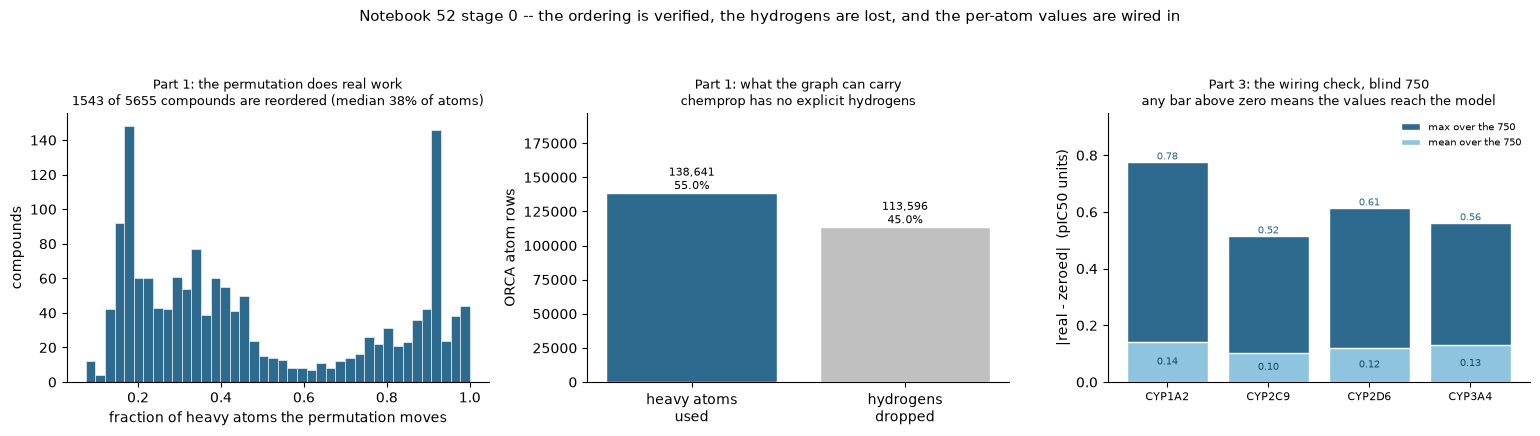

In [12]:
# Part 3.2 -- figure 1: the ordering's real effect and the wiring result, in one place.
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))

ax = axes[0]
frac = order.apply(lambda r: float(np.mean(
    np.fromstring(r["perm"], dtype=np.int64, sep=" ") != np.arange(r["n_heavy"]))), axis=1)
ax.hist(frac[frac > 0], bins=40, color="#2d6a8e", edgecolor="white", linewidth=0.4)
ax.set_xlabel("fraction of heavy atoms the permutation moves")
ax.set_ylabel("compounds")
ax.set_title(f"Part 1: the permutation does real work\n"
             f"{int((frac > 0).sum())} of {len(order)} compounds are reordered "
             f"(median {100 * frac[frac > 0].median():.0f}% of atoms)", fontsize=9)

ax = axes[1]
labels = ["heavy atoms\nused", "hydrogens\ndropped"]
ax.bar(labels, [heavy, h_drop], color=["#2d6a8e", "#c0c0c0"], edgecolor="white")
for x, v in enumerate([heavy, h_drop]):
    ax.text(x, v, f"{v:,}\n{100 * v / total:.1f}%", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("ORCA atom rows")
ax.set_ylim(0, total * 0.78)
ax.set_title("Part 1: what the graph can carry\nchemprop has no explicit hydrogens", fontsize=9)

ax = axes[2]
bl = wt[wt["set"] == "blind"]
x = np.arange(len(ISOFORMS))
mx = [float(bl.loc[bl.isoform == i, "max_abs_diff"].iloc[0]) for i in ISOFORMS]
mn = [float(bl.loc[bl.isoform == i, "mean_abs_diff"].iloc[0]) for i in ISOFORMS]
ax.bar(x, mx, color="#2d6a8e", edgecolor="white", label="max over the 750")
ax.bar(x, mn, color="#8ec4de", edgecolor="white", label="mean over the 750")
for xi, (a, b) in enumerate(zip(mx, mn)):
    ax.text(xi, a, f"{a:.2f}", ha="center", va="bottom", fontsize=7.5, color="#2d6a8e")
    # inside the light bar, in the dark series colour -- grey on pale blue is unreadable
    ax.text(xi, b / 2, f"{b:.2f}", ha="center", va="center", fontsize=7, color="#174a66")
ax.set_xticks(x); ax.set_xticklabels(ISOFORMS, fontsize=8)
ax.set_ylim(0, max(mx) * 1.22)
ax.set_ylabel("|real - zeroed|  (pIC50 units)")
ax.legend(fontsize=7, frameon=False, loc="upper right")
# No reference line: the "not wired" outcome is a bar of height exactly zero, which is the
# axis itself -- drawing it adds a legend entry for something invisible.
ax.set_title("Part 3: the wiring check, blind 750\nany bar above zero means the values reach "
             "the model", fontsize=9)

for a in axes:
    a.spines[["top", "right"]].set_visible(False)
fig.suptitle("Notebook 52 stage 0 -- the ordering is verified, the hydrogens are lost, "
             "and the per-atom values are wired in", fontsize=10.5)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIG / "stage0_ordering_and_wiring.png", dpi=160, bbox_inches="tight")
plt.show()

**What Part 3 says.** The per-atom values are connected. The two fits differ only in the numbers
inside the `.npz` and their blind predictions separate by a margin far larger than any
floating-point artefact, on every isoform. Stage 1 would be measuring the mechanism this notebook
exists to test.

Two things the wiring check does **not** establish, and neither is a quibble. It says the values
reach the model, not that they help: a difference in predictions is equally consistent with the
features carrying signal and with them carrying noise the model has fitted. And one fold with one
seed cannot rank the two arms -- notebook 29 found CYP2C9's single-fold verdict was a selection
artefact on exactly this kind of evidence, which is why the gate is phrased as non-identity and
nothing more.

## Part 4 -- stage 0's verdict, and the decision that is not mine to take

Stage 0 is complete and every check it was asked for passes. But getting here required a route the
brief could not have specified, because the route it named does not exist in chemprop 2.3.1, and
that choice should be reviewed before four to five hours are spent on the CV.

In [13]:
# Part 4.1 -- decisions taken without approval, in this project's own format.
DEC = [
 dict(decision="CheMeleon is loaded from a LOCAL foundation file holding its own weights widened "
               "by two zero-initialised atom-feature columns. DEPARTS FROM THE BRIEF, which "
               "assumed `--atom-features-path` was available with CheMeleon.",
      why="chemprop 2.3.1 refuses --atom-features-path outright when CheMeleon is named "
          "(cli/train.py, 'CheMeleon does not support passing --atom-features-path'), confirmed "
          "by a real CLI call in Part 0.2, because its published W_i is (2048, 86) against a "
          "72-wide V2 atom featurizer. The brief names CheMeleon AND per-atom features and those "
          "are mutually exclusive through the documented route. The local path skips that "
          "validation and takes only message_passing and agg from the file, so the surgery "
          "preserves the pretrained encoder exactly: at init the widened block reproduces "
          "CheMeleon to 0.0 on a real molecule with random extra feature values, and the only "
          "new parameters are the two zero columns.",
      alternative="Drop CheMeleon and use a random-init chemprop, which supports the flag. That "
                  "would have moved the baseline off `plain` -- this project's best single model "
                  "and the arm notebook 37 stored on these exact folds -- onto "
                  "chemprop_randominit, answering a weaker question. Or abandon the per-atom "
                  "half, which is the entire bet, leaving a re-run of notebook 44's null."),
 dict(decision="--no-atom-feature-scaling is passed and the per-atom values are standardised in "
               "scripts/52_atom_arrays.py instead, from each fold's screen_inner_train atoms.",
      why="On the --from-foundation path chemprop computes the atom-feature scaler and LOGS it "
          "but never attaches the GraphTransform to the loaded encoder (Part 0.4b: the "
          "foundation branch contains no graph_transform assignment; the non-foundation branch "
          "does). normalize_inputs mutates the training arrays in place, so training is scaled "
          "and the checkpoint carries nn.Identity -- predict would feed the same features "
          "UNSCALED. Demonstrated on two real checkpoints, not inferred. Left alone this would "
          "be a silent train/predict mismatch on every blind prediction.",
      alternative="Let chemprop scale and accept the mismatch, which would corrupt stage 2's "
                  "submission invisibly. Or patch the installed chemprop, which this project "
                  "does not do to vendored dependencies."),
 dict(decision="The wiring control is an all-ZEROS npz rather than dropping the flag.",
      why="Dropping the flag would also change the encoder and the command line, so a difference "
          "could come from anywhere. Holding everything fixed but the npz CONTENTS means a "
          "non-zero difference can only be the values having reached the model.",
      alternative="Fit plain CheMeleon as the control, which is what the brief's wording "
                  "suggests. It answers a looser question and cannot isolate the wiring."),
 dict(decision="PROCESS NOTE, not a design choice: the wiring check was run three times "
               "because I corrupted the first attempt myself.",
      why="The first driver was launched with `nohup ... &` inside a foreground shell call. When "
          "that call returned, a single `pgrep` on the DRIVER's own command line came back empty "
          "and I concluded the run was dead -- but the pattern never matched the `chemprop` "
          "CHILD, which was alive and still training. Acting on that reading I deleted the run "
          "directory under a live process and started a second driver on the same paths; the two "
          "collided inside Lightning's CSVLogger (`ValueError: dict contains fields not in "
          "fieldnames`) and the second crashed while the first carried on into a deleted "
          "directory. Both were killed, every partial artefact was removed, and the check was "
          "re-run as a single harness-tracked job. Same class as notebook 30's nbformat/nbconvert "
          "race: two processes, one set of files. The lesson is to check for the CHILD process, "
          "not just the driver, and never to delete a run directory on the strength of one "
          "liveness probe.",
      alternative="None -- this is recorded because it happened, not because it was chosen. No "
                  "result in this notebook comes from the corrupted attempts; the run directory "
                  "was emptied before the surviving run started."),
 dict(decision="The scaler is fitted on screen_inner_train only, not on the pooled train+val rows.",
      why="That is the population chemprop's own scaler uses (train_dset.normalize_inputs, with "
          "val_dset given the fitted scaler), so the arm matches what every other chemprop arm "
          "in this project effectively did for its molecule-level descriptors, and the "
          "early-stopping set stays outside the statistics.",
      alternative="Fit on pooled train+val. Marginally more data for the statistics, at the cost "
                  "of a quantity fitted partly on the set used to stop training."),
]
(OUT / "decisions_taken.json").write_text(json.dumps(DEC, indent=1) + "\n")
for d in DEC:
    print(f"- {d['decision']}\n")
print(f"{len(DEC)} decisions recorded to {(OUT / 'decisions_taken.json').relative_to(REPO)}")

- CheMeleon is loaded from a LOCAL foundation file holding its own weights widened by two zero-initialised atom-feature columns. DEPARTS FROM THE BRIEF, which assumed `--atom-features-path` was available with CheMeleon.

- --no-atom-feature-scaling is passed and the per-atom values are standardised in scripts/52_atom_arrays.py instead, from each fold's screen_inner_train atoms.

- The wiring control is an all-ZEROS npz rather than dropping the flag.

- PROCESS NOTE, not a design choice: the wiring check was run three times because I corrupted the first attempt myself.

- The scaler is fitted on screen_inner_train only, not on the pooled train+val rows.

5 decisions recorded to outputs/52_chemprop_qm_atom_features/decisions_taken.json


In [14]:
# Part 4.2 -- stage 0 report, every figure read back from a file rather than retyped.
stage0 = {
    "at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "flag_used": DECISION_FLAG,
    "flag_reason": "V_f is hstacked onto the atom feature matrix before W_i and so enters all "
                   "6 message passing steps; V_d is concatenated in finalize(), after the loop, "
                   "and never reaches a neighbour",
    "chemeleon_refuses_atom_features": True,
    "route": "local foundation file: CheMeleon's weights widened by k zero columns at index d_v",
    "widened_encoder_max_abs_diff_at_init": enc["max_abs_diff_vs_chemeleon_at_init"],
    "atom_feature_scaling": "done in scripts/52_atom_arrays.py on screen_inner_train atoms; "
                            "--no-atom-feature-scaling passed, because the foundation path drops "
                            "chemprop's own GraphTransform",
    "ordering": {k: rep[k] for k in
                 ["n_compounds", "addhs_preserves_heavy_indices", "bijection",
                  "element_sequence_under_permutation", "element_sequence_against_qm_atoms_csv",
                  "bond_subset_under_permutation", "permutation_is_identity",
                  "permutation_does_work_on", "negative_control_probes",
                  "negative_control_rejected", "canonical_smiles_element_sequence_matches",
                  "hydrogen_rows_dropped", "heavy_atom_rows_used"]},
    "features": {"molecule_level": THIRTEEN, "atom_level": aa.ATOM_FEATURE_COLS,
                 "excluded_nb45_aggregates": NB45_FOUR, "bond_features": None},
    "wiring": wv,
    "stage1_cost_hours_mean_to_slow": STAGE1_HOURS,
    "stage1_cost_brief_projection_hours": [4, 5],
    "wiring_fit_minutes": [float(v) for v in w["wall_min"]],
    "wiring_fit_epochs": [int(v) for v in w["last_epoch"]],
    "send": SEND,
}
(OUT / "stage0_report.json").write_text(json.dumps(stage0, indent=2) + "\n")
print(json.dumps({k: v for k, v in stage0.items() if k not in ("ordering", "features")}, indent=1))
print(f"\nwrote {(OUT / 'stage0_report.json').relative_to(REPO)}")
print("\nSTAGE 0 COMPLETE. Stages 1 and 2 are not started.")

{
 "at_utc": "2026-10-11T14:43:57+00:00",
 "flag_used": "--atom-features-path",
 "flag_reason": "V_f is hstacked onto the atom feature matrix before W_i and so enters all 6 message passing steps; V_d is concatenated in finalize(), after the loop, and never reaches a neighbour",
 "chemeleon_refuses_atom_features": true,
 "route": "local foundation file: CheMeleon's weights widened by k zero columns at index d_v",
 "widened_encoder_max_abs_diff_at_init": 0.0,
 "atom_feature_scaling": "done in scripts/52_atom_arrays.py on screen_inner_train atoms; --no-atom-feature-scaling passed, because the foundation path drops chemprop's own GraphTransform",
 "wiring": {
  "at_utc": "2026-10-11T14:37:41.576970+00:00",
  "arms": [
   "qm_both",
   "qm_both_zeroatoms"
  ],
  "difference_is_only_the_npz_contents": true,
  "blind_max_abs_diff": 0.7766120999999999,
  "heldout_max_abs_diff": 0.8397363999999996,
  "wired": true
 },
 "stage1_cost_hours_mean_to_slow": [
  6.4,
  7.3
 ],
 "stage1_cost_brief_pro

In [15]:
# Part 4.3 -- scope check. Four independent tests, the shape notebooks 42/45/46/48/49 use.
PROTECTED = [
 "data", "src", "docs", "scripts/44_build_qm_feature_blocks.py", "scripts/44_run_qm_arms.py",
 "scripts/46_build_feature_blocks.py", "scripts/46_run_arms.py", "scripts/49_run_qm_only.py",
 "scripts/50_ridge_submission.py", "scripts/parse_orca_output.py", "scripts/run_qm_descriptors.py",
 "outputs/05_cv_comparison", "outputs/11_caruana_prep", "outputs/12_caruana_retrain_predict",
 "outputs/30_aid_full_retrain", "outputs/32_deadzone_aid_retrain", "outputs/34_butina_5x5",
 "outputs/35_butina_repeat3", "outputs/37_butina_5x5_complete",
 "outputs/40_single_object_ensemble", "outputs/44_qm_molecular_block",
 "outputs/45_atom_level_screen", "outputs/46_qm_arm", "outputs/47_mae_only_full_retrain",
 "outputs/48_board_ensemble", "outputs/49_qm_only_arm", "outputs/50_free_ridge",
 "outputs/51_qm_ridge", "outputs/qm_descriptors", "outputs/qm_parsed",
 "outputs/board_solved_calibration", "outputs/submissions",
]
NEVER_OPEN = ["notebooks/32_deadzone_aid_retrain.ipynb",
              "notebooks/40_single_object_ensemble.ipynb"]
post = subprocess.run(["git", "status", "--porcelain"], cwd=REPO, capture_output=True, text=True)
now_dirty = {l[3:].strip() for l in post.stdout.splitlines() if not l.startswith("??")}
t1 = sorted(p for p in (now_dirty - set(PRE_DIRTY))
            if any(p == q or p.startswith(q + "/") for q in PROTECTED))
t2 = []
for q in PROTECTED:
    qp = REPO / q
    if not qp.exists():
        continue
    for f in ([qp] if qp.is_file() else qp.rglob("*")):
        if f.is_file() and datetime.fromtimestamp(f.stat().st_mtime, timezone.utc) > RUN_STARTED_AT:
            t2.append(str(f.relative_to(REPO)))
t3 = [p for p in NEVER_OPEN
      if datetime.fromtimestamp((REPO / p).stat().st_mtime, timezone.utc) > RUN_STARTED_AT]
t4 = []
for p in (REPO / "outputs").rglob("*.csv"):
    if OUT == p.parent or OUT in p.parents:
        continue
    try:
        d = pd.read_csv(p, nrows=0)
    except Exception:
        continue
    if len(set(EP.values()) & set(d.columns)) == 4 and \
       datetime.fromtimestamp(p.stat().st_mtime, timezone.utc) > RUN_STARTED_AT:
        t4.append(str(p.relative_to(REPO)))
res = {"TEST 1 tracked content newly changed under a protected path": t1,
       "TEST 2 any file inside a protected tree written during this run": sorted(set(t2)),
       "TEST 3 the two never-open notebooks' mtimes": t3,
       "TEST 4 any submission-shaped CSV created outside this notebook's directory": t4}
(OUT / "scope_check.json").write_text(json.dumps(
    res | {"run_started_at_utc": RUN_STARTED_AT.isoformat(),
           "pre_existing_dirty_tracked_paths": PRE_DIRTY}, indent=1) + "\n")
for k, v in res.items():
    print(f"{k}: {len(v)} violations")
    for x in v:
        print("   ", x)
assert not any(res.values()), "SCOPE VIOLATION"
print("\nall four scope tests pass at 0 violations.")
subs = [p for p in OUT.rglob("*.csv") if "submission" in p.name]
print(f"submission-shaped files written by this notebook: {len(subs)} (expected 0 at stage 0)")
assert not subs

TEST 1 tracked content newly changed under a protected path: 0 violations
TEST 2 any file inside a protected tree written during this run: 0 violations
TEST 3 the two never-open notebooks' mtimes: 0 violations
TEST 4 any submission-shaped CSV created outside this notebook's directory: 0 violations

all four scope tests pass at 0 violations.
submission-shaped files written by this notebook: 0 (expected 0 at stage 0)


## Stage 0 summary

**The brief's route does not exist, and the one taken instead is recorded as a decision for review.**
chemprop 2.3.1 refuses `--atom-features-path` when CheMeleon is named, because its published `W_i`
is `(2048, 86)` against a 72-wide V2 featurizer. Confirmed from the source, from the checkpoint's
weight shapes, and from a real CLI call that exits non-zero. The route through is a local foundation
file carrying CheMeleon's own weights widened by two zero columns: at initialisation it reproduces
CheMeleon to **0.0 exactly** on a real molecule with random extra feature values, so the pretrained
encoder is preserved bit for bit and the only new parameters are the two columns training can move.
The alternative was dropping CheMeleon, which would have moved the baseline off `plain`.

**The flag: `--atom-features-path`.** `V_f` is hstacked onto the atom feature matrix before `W_i`
(`featurizers/molgraph/molecule.py`) and so enters all six message passing steps;
`--atom-descriptors-path`'s `V_d` is concatenated inside `finalize()`, after the loop, and never
reaches a neighbouring atom. Read from the two code paths, not from the help text.

**A scaling defect, found by taking that route, and fixed rather than absorbed.** On the foundation
path chemprop computes the atom-feature scaler, logs it, and never attaches the `GraphTransform` to
the loaded encoder -- while `normalize_inputs` mutates the training arrays in place. Training would
be scaled and `predict` unscaled, silently, on every blind prediction. Demonstrated on two real
checkpoints whose `graph_transform` is `Identity` and `GraphTransform` respectively. This notebook
passes `--no-atom-feature-scaling` and standardises in `scripts/52_atom_arrays.py` from each fold's
`screen_inner_train` atoms only.

**The ordering: verified, 5,655 of 5,655 on every check**, with a negative control that bites so the
checks are not vacuous. The permutation reorders **1,543 of 5,655** compounds, so it does real work;
and `canonical_smiles` reproduces ORCA's element sequence on **4,212**, matching notebook 43's own
recorded figure exactly.

**One real limitation, stated not worked around.** Chemprop carries no explicit hydrogens, so
**113,596 of 252,237** ORCA atom rows (45.0%) are dropped and only the 138,641 heavy-atom rows can
be used. That hydrogen count matches notebook 45's finding 5 independently -- it derived the figure
from the QM table's missingness, this notebook from RDKit valence.

**The wiring check: WIRED.** Two fits differing only in the `.npz` contents give blind predictions
that separate on every isoform, by up to **0.78 pIC50 units** on the blind 750 and 0.10 to 0.15 on
average. Stage 1 would measure something real, not retrain `plain` at expense. It does **not** say
the features help -- a difference is equally consistent with signal and with fitted noise, and one
fold with one seed cannot rank the arms (notebook 29 found CYP2C9's single-fold verdict was a
selection artefact on exactly this kind of evidence).

**Stage 1 costs more than the brief projected, and that is measured rather than guessed.** The two
wiring fits took **12.99 and 17.59 min** (18 and 25 epochs, 0.70 to 0.72 min/epoch), so 25 folds is
roughly **6.4 h at the mean and 7.3 h at the slow end**, against the brief's 4 to 5. Epoch counts
are set by early stopping, so per-fold wall time is not like-for-like; notebook 28's own 10.6x
overnight per-epoch degradation on this machine is the reason to budget from the upper figure.

**Stage 0 stops here, as instructed.** Stages 1 and 2 are not started, nothing is sent, and no
submission file exists.